# Pokédex intelligent — Niveaux 2 et 3 : images

- **Niveau 2** : prédire le ou les **types** d'un Pokémon à partir de son image.
- **Niveau 3** : **identifier** le Pokémon sur l'image (pour afficher sa fiche dans l'appli).

Les calculs sont faits par `entrainer.py` (long : extraction des caractéristiques de ~17 000 images).
Ce notebook relit ses résultats (`resultats/`) et les commente.

## Méthode : transfer learning
1. Chaque image est mise au format 224×224 (fond blanc, sans déformation).
2. Un réseau **MobileNetV2 pré-entraîné sur ImageNet** (gelé, non ré-entraîné) la transforme en un vecteur de
   **1280 caractéristiques**.
3. Des classifieurs classiques apprennent sur ces vecteurs : régression logistique, k-NN (cosinus),
   forêt aléatoire, MLP (petit réseau de neurones).
4. **Référence sans deep learning** : histogramme de couleurs HSV (256 valeurs) → montre l'apport du CNN.

Pourquoi ne pas entraîner un CNN de zéro ? Sans GPU ce serait très long, et ~120 images par Pokémon, c'est peu :
le réseau pré-entraîné « sait déjà voir » des formes et des textures.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 3)
eff = pd.read_csv("resultats/effectifs_par_pokemon.csv", index_col=0).iloc[:, 0]
print(f"{eff.sum()} images, {len(eff)} Pokémon ; images par Pokémon : min {eff.min()}, "
      f"médiane {eff.median():.0f}, max {eff.max()}")

17261 images, 142 Pokémon ; images par Pokémon : min 61, médiane 120, max 218


## Protocole d'évaluation
- **80 % / 20 % stratifié par Pokémon** : chaque Pokémon a ~20 % de ses images dans le jeu de test.
- Métriques choisies pour mesurer la **couverture** (consigne : ne pas être bon que sur les Pokémon faciles) :
  - **accuracy équilibrée** = moyenne des taux de reconnaissance de chaque Pokémon (chacun compte pareil) ;
  - **couverture 50 % / 80 %** = part des Pokémon reconnus sur au moins 50 % / 80 % de leurs images ;
  - top-5 : le bon Pokémon est parmi les 5 propositions.

## Niveau 3 — Identification du Pokémon

In [2]:
id3 = pd.read_csv("resultats/niveau3_identification.csv", index_col=0)
id3

,accuracy,accuracy_equilibree,f1_macro,top5,couverture_50%,couverture_80%,temps (s)
Approche,,,,,,,
CNN MobileNetV2 + Régression logistique,0.836,0.829,0.831,0.955,0.993,0.662,9.368
CNN MobileNetV2 + MLP (1 couche cachée),0.812,0.800,0.802,0.948,0.986,0.556,25.297
"CNN MobileNetV2 + k-NN (k=5, cosinus)",0.721,0.707,0.714,0.850,0.951,0.254,0.728
CNN MobileNetV2 + Forêt aléatoire,0.696,0.671,0.684,0.840,0.824,0.282,63.034
Histogramme couleurs + Forêt aléatoire,0.591,0.573,0.580,0.789,0.761,0.077,10.256
Histogramme couleurs + Régression logistique,0.353,0.340,0.342,0.608,0.155,0.007,16.210


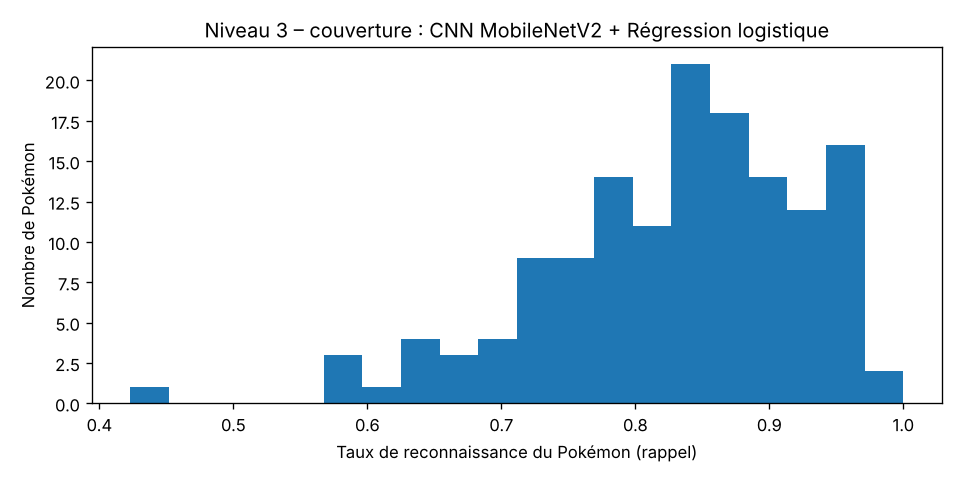

,taux_de_reconnaissance
pokemon,
Pidgeotto,0.423
Abra,0.583
Machoke,0.588
Rattata,0.591
Alakazam,0.611
Grimer,0.625
Mew,0.632
Kangaskhan,0.632
Ponyta,0.652


In [3]:
display(Image("resultats/niveau3_couverture.png"))
pd.read_csv("resultats/niveau3_pokemon_les_moins_reconnus.csv", index_col=0)

**Analyse** :
- le CNN écrase l'histogramme de couleurs : la couleur seule ne suffit pas (beaucoup de Pokémon partagent
  les mêmes couleurs) ;
- la **régression logistique** sur les caractéristiques CNN est le meilleur compromis (meilleure accuracy
  équilibrée, rapide, modèle léger) => **modèle retenu** ;
- presque tous les Pokémon sont reconnus sur au moins la moitié de leurs images ; les plus difficiles sont des
  **évolutions qui se ressemblent** (Pidgeotto/Pidgeot, Abra/Kadabra/Alakazam, Drowzee/Hypno...).

## Niveau 2 — Types à partir de l'image

Problème **multi-label** : 1 ou 2 types par Pokémon. Règle de décision : on garde les types de probabilité ≥ 0,5
(au plus 2) et au minimum le plus probable.
Métriques : **exact** (exactement les bons types), au moins 1 type correct, F1 micro / **macro** (chaque type compte
autant), couverture (part des Pokémon dont ≥ 50 % des images ont exactement les bons types).

Deux approches comparées :
- **directe** : image → types ;
- **via l'identification** : P(type) = somme des probabilités des Pokémon qui ont ce type.

In [4]:
pd.read_csv("resultats/niveau2_types_pokemon_connus.csv", index_col=0)

,exact,au_moins_1_type_correct,f1_micro,f1_macro,couverture_50%,temps (s)
Approche,,,,,,
Via identification : CNN MobileNetV2 + Régression logistique,0.874,0.911,0.907,0.907,1.000,9.337
Direct : CNN + MLP (1 couche cachée),0.730,0.866,0.833,0.828,0.901,12.463
"Direct : CNN + k-NN (k=5, cosinus)",0.761,0.836,0.828,0.821,0.951,0.640
Direct : CNN + Régression logistique,0.559,0.812,0.733,0.750,0.613,5.269
Direct : CNN + Forêt aléatoire,0.378,0.654,0.579,0.439,0.268,41.002


### Et pour un Pokémon jamais vu ?
Ici, **toutes les images d'un même Pokémon** sont dans le même pli (GroupKFold, 5 plis) : le modèle doit deviner les
types d'un Pokémon qu'il n'a jamais vu. L'approche via l'identification est alors impossible.

In [5]:
pd.read_csv("resultats/niveau2_types_pokemon_inconnus.csv", index_col=0)

,exact,au_moins_1_type_correct,f1_micro,f1_macro,couverture_50%,temps (s)
Approche,,,,,,
Direct : CNN + Régression logistique,0.197,0.488,0.395,0.355,0.077,20.905
"Direct : CNN + k-NN (k=5, cosinus)",0.251,0.432,0.382,0.332,0.148,3.697
Direct : CNN + MLP (1 couche cachée),0.270,0.516,0.444,0.395,0.190,109.113
Référence (type le plus fréquent),0.133,0.218,0.178,0.021,0.120,0.000


**Analyse et choix** :
- sur des Pokémon **connus**, passer par l'identification est le plus fiable : le type d'un Pokémon reconnu est
  connu grâce au Pokédex ;
- sur des Pokémon **inconnus**, c'est beaucoup plus dur (environ 25 % de prédictions exactes), mais nettement
  mieux que la référence. Le modèle a appris des indices visuels (couleurs dominantes, ailes, flammes...) ;
- **modèle retenu pour l'appli** : le **meilleur classifieur direct** (MLP), parce qu'il marche aussi pour un
  Pokémon hors dataset. L'appli affiche en plus le Pokémon reconnu et ses vrais types.

## Limites et pistes d'amélioration
- dataset « du web » : images hétérogènes (dessins, figurines, cartes, fan-arts), quelques erreurs d'étiquetage ;
- seulement la 1re génération, et ~120 images par Pokémon ;
- CNN gelé : un **fine-tuning** des dernières couches de MobileNetV2 avec de l'**augmentation de données**
  (rotations, recadrages) améliorerait sûrement les résultats, au prix d'un entraînement bien plus long (GPU conseillé) ;
- types sur Pokémon inconnus : peu d'exemples pour certains types (Ice, Dragon, Ghost).